# Phân tích tối ưu hóa và Renju

## Mục tiêu và phạm vi
Đối chiếu hiệu năng Python/C++ MCTS, batching và multiprocessing theo đúng workload đã đo; đặt các kết quả Renju và tactical probe trong bối cảnh fine-tuning thực có. Notebook chỉ đọc mã, tài liệu, CSV, log và SQLite ở chế độ chỉ đọc. **Không chạy training, self-play, benchmark hoặc tournament; không sửa dữ liệu nguồn.**

Các con số benchmark dưới đây là số đã được ghi nhận trong báo cáo, không phải phép đo mới. Protocol khác nhau được giữ thành các hàng/nhóm tách biệt: 2,54× là self-play 8 games/run, còn kết quả worker ở batch 50 là một benchmark vận hành khác. Không quy tốc độ thành sức chơi; loss giảm không hàm ý strength tăng.

Nguồn chính: `SPEC.md` §§7, 9, 11–12; `docs/cpp-real-world-benchmark.md`; `docs/performance/11-production-benchmark.md`; `docs/benchmarks.md`; `report/chapters_5.md` §§5.6–5.7; `.audit/renju_diagnostic_20261123.md`; `experiment_results.csv`; `working_details.csv`; source `az/backend.py`, `az/selfplay.py`, `az/mcts.py`, `az/renju_finetune.py`, `scripts/bench_real_world.py`. Các đường dẫn trong notebook tính từ root repository.


In [1]:
%matplotlib inline
from pathlib import Path
import csv, sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Hỗ trợ chạy từ root repo hoặc thư mục notebooks; không hard-code ổ đĩa máy soạn.
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents) if (p / 'SPEC.md').is_file()), HERE)
print('Repository root:', ROOT)
try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    plt.style.use('seaborn-whitegrid')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})

def repo_path(path):
    return ROOT / path

for p in ['SPEC.md', 'docs/cpp-real-world-benchmark.md', 'docs/performance/11-production-benchmark.md', 'report/chapters_5.md']:
    print(('OK     ' if repo_path(p).is_file() else 'THIẾU  ') + p)

Repository root: D:\PycharmProject\SGU-TriTueNhanTaoNangCao\AlphaZero_Gomoku
OK     SPEC.md
OK     docs/cpp-real-world-benchmark.md
OK     docs/performance/11-production-benchmark.md
OK     report/chapters_5.md


## Cách đọc bằng chứng và kiến trúc liên quan
`az/backend.py::configure_backends` chọn component MCTS/Patterns; backend `cpp` là native search tree qua pybind11, không phải engine toàn C++. `az/selfplay.py::run_games` đan xen games và gom các leaf requests để gọi `model.predict` theo batch. Python vẫn giữ Board, Rules, feature extraction, RNG và PyTorch inference. Vì vậy throughput phản ánh cả search/request orchestration, batching và GPU inference, không chỉ tốc độ C++ tree.

SPEC §7.1 cố định ngân sách AZ MCTS ở 200 simulations cho self-play/đánh giá. Không so trực tiếp simulations với AlphaBeta depth hoặc budget MCTS Pure; các workload tournament time-budget cũng không tương đương. `docs/cpp-real-world-benchmark.md` đo một ván batch=1 và self-play nhiều ván batch=16 — hai cấu hình có tỷ trọng inference rất khác.


In [2]:
# Bảng định lượng chép từ các báo cáo nguồn, giữ protocol riêng biệt.
bench = pd.DataFrame([
 {'Nhóm protocol':'Self-play ngắn, 8 games/run','Backend':'Python','Cấu hình':'Normal; 200 sims; G=16; 3 seeds × 2 repeats','Tốc độ':0.255,'Đơn vị':'games/s','Nguồn':'docs/cpp-real-world-benchmark.md §2–3'},
 {'Nhóm protocol':'Self-play ngắn, 8 games/run','Backend':'C++','Cấu hình':'Normal; 200 sims; G=16; 3 seeds × 2 repeats','Tốc độ':0.648,'Đơn vị':'games/s','Nguồn':'docs/cpp-real-world-benchmark.md §2–3'},
 {'Nhóm protocol':'Iteration 50 game, 1 worker','Backend':'Python','Cấu hình':'Normal; 200 sims; 3 lần đo','Tốc độ':22.91,'Đơn vị':'games/min','Nguồn':'docs/performance/11-production-benchmark.md §6'},
 {'Nhóm protocol':'Iteration 50 game, 1 worker','Backend':'C++','Cấu hình':'Normal; 200 sims; 3 lần đo','Tốc độ':86.51,'Đơn vị':'games/min','Nguồn':'docs/performance/11-production-benchmark.md §6'},
 {'Nhóm protocol':'Iteration 50 game, 2 workers','Backend':'Python','Cấu hình':'25 games/worker; 200 sims; 3 lần đo','Tốc độ':54.08,'Đơn vị':'games/min','Nguồn':'docs/performance/11-production-benchmark.md §6'},
 {'Nhóm protocol':'Iteration 50 game, 2 workers','Backend':'C++','Cấu hình':'25 games/worker; 200 sims; 3 lần đo','Tốc độ':129.59,'Đơn vị':'games/min','Nguồn':'docs/performance/11-production-benchmark.md §6'},
 {'Nhóm protocol':'Iteration 50 game, 4 workers','Backend':'Python','Cấu hình':'13/13/12/12 games/worker; 200 sims; 3 lần đo','Tốc độ':80.05,'Đơn vị':'games/min','Nguồn':'docs/performance/11-production-benchmark.md §6'},
 {'Nhóm protocol':'Iteration 50 game, 4 workers','Backend':'C++','Cấu hình':'13/13/12/12 games/worker; 200 sims; 3 lần đo','Tốc độ':124.66,'Đơn vị':'games/min','Nguồn':'docs/performance/11-production-benchmark.md §6'},
])
bench

,Nhóm protocol,Backend,Cấu hình,Tốc độ,Đơn vị,Nguồn
0,"Self-play ngắn, 8 games/run",Python,Normal; 200 sims; G=16; 3 seeds × 2 repeats,0.255,games/s,docs/cpp-real-world-benchmark.md §2–3
1,"Self-play ngắn, 8 games/run",C++,Normal; 200 sims; G=16; 3 seeds × 2 repeats,0.648,games/s,docs/cpp-real-world-benchmark.md §2–3
2,"Iteration 50 game, 1 worker",Python,Normal; 200 sims; 3 lần đo,22.910,games/min,docs/performance/11-production-benchmark.md §6
3,"Iteration 50 game, 1 worker",C++,Normal; 200 sims; 3 lần đo,86.510,games/min,docs/performance/11-production-benchmark.md §6
4,"Iteration 50 game, 2 workers",Python,25 games/worker; 200 sims; 3 lần đo,54.080,games/min,docs/performance/11-production-benchmark.md §6
5,"Iteration 50 game, 2 workers",C++,25 games/worker; 200 sims; 3 lần đo,129.590,games/min,docs/performance/11-production-benchmark.md §6
6,"Iteration 50 game, 4 workers",Python,13/13/12/12 games/worker; 200 sims; 3 lần đo,80.050,games/min,docs/performance/11-production-benchmark.md §6
7,"Iteration 50 game, 4 workers",C++,13/13/12/12 games/worker; 200 sims; 3 lần đo,124.660,games/min,docs/performance/11-production-benchmark.md §6


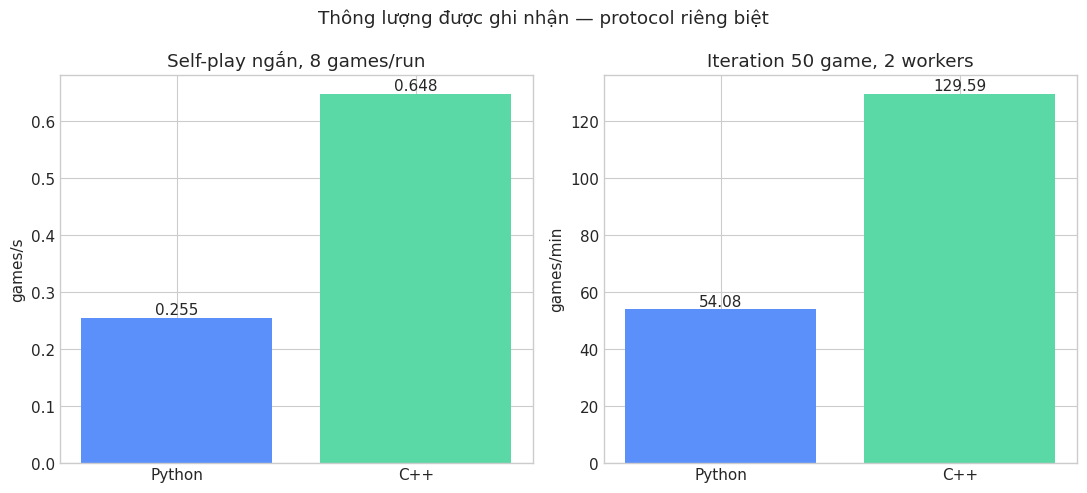

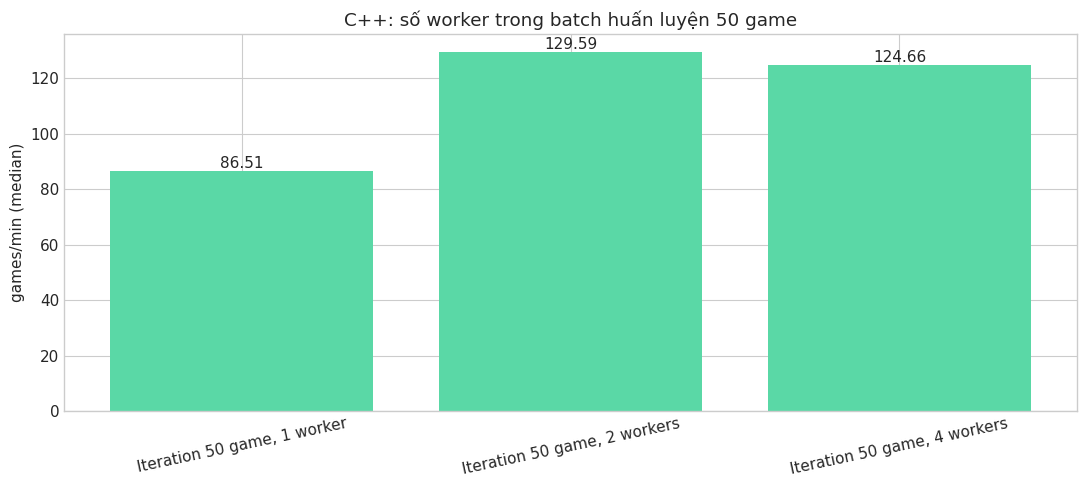

In [3]:
# So sánh trong từng protocol, không trộn games/s với games/min.
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, group in zip(axes, ['Self-play ngắn, 8 games/run', 'Iteration 50 game, 2 workers']):
    d = bench[bench['Nhóm protocol'] == group]
    bars = ax.bar(d['Backend'], d['Tốc độ'], color=['#5B8FF9', '#5AD8A6'])
    ax.set_title(group)
    ax.set_ylabel(d['Đơn vị'].iloc[0])
    for bar, value in zip(bars, d['Tốc độ']):
        ax.annotate(f'{value:g}', (bar.get_x()+bar.get_width()/2, bar.get_height()), ha='center', va='bottom')
fig.suptitle('Thông lượng được ghi nhận — protocol riêng biệt')
fig.tight_layout()
plt.show()

# Worker-count comparison chỉ ở iteration batch=50; hiển thị riêng để tránh tráo workload.
worker_cpp = bench[(bench['Backend']=='C++') & bench['Nhóm protocol'].str.startswith('Iteration 50 game')]
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(worker_cpp['Nhóm protocol'], worker_cpp['Tốc độ'], color='#5AD8A6')
ax.set_ylabel('games/min (median)')
ax.set_title('C++: số worker trong batch huấn luyện 50 game')
ax.tick_params(axis='x', rotation=12)
for bar, value in zip(bars, worker_cpp['Tốc độ']): ax.annotate(f'{value:g}', (bar.get_x()+bar.get_width()/2, bar.get_height()), ha='center', va='bottom')
fig.tight_layout()
plt.show()

## Diễn giải benchmark: workload, multiprocessing và MCTS
| Đo lường | Kết quả ghi nhận | Protocol/giới hạn |
|---|---|---|
| Python vs C++ | 0,255 vs 0,648 games/s; 2,54× throughput median | RTX 4060 Laptop, Windows, Python 3.10.6, torch 2.14.1+cu126, `checkpoints/latest.pt`, Normal, 200 sims, G=16, 8 game/run, seeds 1–3 × 2 repeats. 39.495 inference calls và mean batch 7,63 ở mỗi backend; hai summary này không chứng minh mọi request/batch giống nhau. |
| C++ vs Python, iteration 50 games | 1 worker: 86,51 vs 22,91; 2 workers: 129,59 vs 54,08; 4 workers: 124,66 vs 80,05 games/min | RTX 4060, checkpoint `last.pt` SHA `6e29a4e3…ffbc`, 200 sims, ba lần/config; 2 workers tốt nhất cho đúng workload 50 games và RSS 3,36 GB, 4 workers 5,42 GB. Không phải tối ưu phổ quát. |
| Giữ tổng 16 games, C++ | 1/2/4 workers: 60,34 / 73,27 / 53,02 games/min | Ba lần đo; bốn workers dùng RSS 5,23 GB. Overhead process/memory làm scaling không tuyến tính. |
| Saturation, 16 games/worker, C++ | 1/2/4 workers: 66,03 / 100,68 / 156,73 games/min | Một lần/config; workload tổng tăng 16→32→64 games, không phải iteration training 50 game. 4 workers: RSS 5,60 GB. |
| Multiprocessing spike lịch sử | 1 process, G=16: 84,3 s/16 games; 4 process × 4 games: 39,5 s/16 games (2,13×) | `docs/benchmarks.md` §GĐ5 ghi spike chưa tích hợp vào train; khác ngày/checkpoint/protocol với production benchmark, không gộp trực tiếp. |
| MCTS tree-only | Python 464,23 ms; C++ 274,34 ms (1,69×), visits trùng | Cùng board, evaluator và 200 sims; phép đo tree-only riêng, không dự đoán end-to-end speedup. |

Trong end-to-end benchmark 2,54×, báo cáo phase timing phân bổ inference 53,3% wall ở Python và 79,7% ở C++; non-inference 14,378→2,502 s (5,75×), inference 16,829→9,851 s (1,71×). Một vị trí batch=1 lại cho inference 92–95%; khác biệt đến từ batching nhiều games. Tree MCTS chỉ ~2% trong profile một ván nên không có chứng cứ rằng tree là bottleneck chính. Không ngoại suy speedup sang tournament, training đầy đủ hay phần cứng khác.

Nguồn: `docs/cpp-real-world-benchmark.md` §§2–10; `docs/performance/11-production-benchmark.md` §§1–8; `docs/benchmarks.md` §§GĐ3–GĐ5; `scripts/bench_real_world.py`; `az/selfplay.py`; `az/backend.py`; `SPEC.md` §§7.1, 9.1–9.3.

## Renju fine-tuning và tactical evidence
Fine-tune đổi luật Normal → Renju, dùng replay tách ruleset; cấu hình `configs/renju.yaml` đặt 4 plies opening ngẫu nhiên, 40% games có một bên đi nước hợp lệ ngẫu nhiên, Dirichlet ε=0,35, batch 50, 200 sims. `az/renju_finetune.py` tiếp tục checkpoint với optimizer/training state mới theo implementation. Đó là yếu tố của protocol, không phải bằng chứng thành công.

| Bằng chứng | Quan sát | Cách kết luận |
|---|---|---|
| Run Renju 500 games | train loss 3,16399→3,57626; value loss 0,15362→0,45555; fixed-batch loss 3,33481→3,45334 | Loss tăng không nói strength tăng/giảm; đường dẫn source checkpoint cũ thiếu hash. |
| Replay Renju 1.500 games | 1.500/1.500 game Black-win, 0 hòa; 14.308 samples: Black-to-move `z=+1` 7.904, White-to-move `z=-1` 6.404 | Outcome một phía làm value training suy biến; nhãn theo góc nhìn player-to-move được audit thấy đúng. |
| Tactical forced-block, cùng 10 positions | checkpoint 500: chặn 0/10; checkpoint 1.500: chặn 10/10, 200 C++ simulations | Bằng chứng cải thiện trên tập tình huống cố định, không đại diện tactical generalization. |
| Tournament Renju 1.500 vs Heuristic | 32 thắng, 0 hòa, 68 thua/100 (score 32%); Black 13–37, White 19–31 | Không đạt mục tiêu 70%; chỉ một screen mỗi checkpoint, không ước lượng strength ổn định. |
| Tournament Renju 500 vs Heuristic | 0–0–100; missed all 10 unique blocks trong các thế White có đúng một block | Không quy toàn bộ thua cuộc cho missed blocks: replay cùng continuation vẫn thua 10/10. |

Hai checkpoint screen dùng 50 cặp đổi màu, cùng seeds và opening prefixes 4 ply, 200 C++ simulations, không tactical override. Dù protocol screen tương đối matched, 500-game checkpoint không có source identity, không có matched pre/post fine-tuning từ cùng source, và không có repeated independent tournaments. Bởi vậy không thể kết luận fine-tuning gây tăng strength tổng thể. Tác động chiến thuật chỉ được ghi nhận ở 10 thế đã chọn.

Audit Renju ghi checkpoint 500 SHA `42bdd1c9…55870`; checkpoint 1.500 SHA `5e2e45d5…af9b5`, nguồn Normal generation SHA `17ab2889…2aa46` theo audit nhưng lineage trực tiếp chưa đối chiếu hoàn tất. Checkpoint 10.000-game và logs trận của nó không có trong worktree đã khảo sát. Không gọi model 1.500 games là model 10k. Luật Renju là semantics của implementation hiện tại, không phải chứng minh tương đương toàn bộ luật quốc tế (`SPEC.md` §5.2).

Nguồn: `.audit/renju_diagnostic_20261123.md` §§1–4; `report/chapters_5.md` §5.6; `docs/report.md` §§8.2–8.3; `configs/renju.yaml`; `az/renju_finetune.py`; `SPEC.md` §§5.2, 8.3.

In [4]:
# Kiểm kê động: dùng schema tiếng Việt đang có; CSV và SQLite chỉ đọc.
def read_csv_if_present(path):
    p = repo_path(path)
    if not p.is_file():
        print(f'THIẾU: {path}')
        return pd.DataFrame()
    try:
        df = pd.read_csv(p, encoding='utf-8-sig', low_memory=False)
        print(f'{path}: {len(df):,} dòng × {len(df.columns)} cột')
        return df
    except Exception as exc:
        print(f'Không đọc được {path}: {exc}')
        return pd.DataFrame()

experiments = read_csv_if_present('experiment_results.csv')
details = read_csv_if_present('working_details.csv')
if not experiments.empty:
    print('Cột experiment_results.csv:', list(experiments.columns))
    if 'Nhóm thí nghiệm' in experiments:
        display(experiments[experiments['Nhóm thí nghiệm'].astype(str).str.contains('Hiệu năng|Renju', case=False, na=False)].head(30))
if not details.empty:
    print('Cột chính working_details.csv:', [c for c in ['Nhóm thí nghiệm','Loại bản ghi','Mã run','Số ván trong bản ghi','Tốc độ','Nguồn trong Git','Nguồn SQLite local'] if c in details.columns])
    if 'Nhóm thí nghiệm' in details:
        display(details[details['Nhóm thí nghiệm'].astype(str).str.contains('Hiệu năng|Renju', case=False, na=False)].head(20))

# SQLite: mode=ro bảo đảm không tạo/sửa DB. Chỉ liệt kê schema, không đếm/scans bảng dữ liệu lớn.
db_candidates = ['data/tournament.sqlite', 'data/renju_finetune_1500.sqlite', 'data/selfplay.sqlite', 'data/normal.sqlite', 'data/renju_diagnostic_screen_20261123.sqlite']
db_inventory = []
for rel in db_candidates:
    p = repo_path(rel)
    if not p.is_file():
        db_inventory.append({'Tệp':rel, 'Trạng thái':'Thiếu (thường bị Git ignore trong clone)', 'MB':None, 'Bảng':None})
        continue
    try:
        uri = p.resolve().as_uri() + '?mode=ro'
        with sqlite3.connect(uri, uri=True, timeout=2) as con:
            tables = [r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")]
        db_inventory.append({'Tệp':rel, 'Trạng thái':'Đọc metadata thành công (read-only)', 'MB':round(p.stat().st_size/1024**2,2), 'Bảng':', '.join(tables[:12]) + (' …' if len(tables)>12 else '')})
    except Exception as exc:
        db_inventory.append({'Tệp':rel, 'Trạng thái':f'Không mở được read-only: {exc}', 'MB':round(p.stat().st_size/1024**2,2), 'Bảng':None})
display(pd.DataFrame(db_inventory))

# Kiểm tra raw benchmark JSON và logs được report trích dẫn; chỉ liệt kê sự hiện diện/dung lượng.
for pattern in ['docs/performance/raw-round2-*.json', 'data/*renju*.log', 'data/*selfplay*.log']:
    found = sorted(ROOT.glob(pattern))
    print(pattern, '→', [(str(p.relative_to(ROOT)), round(p.stat().st_size/1024,1)) for p in found] if found else 'không có trong clone/worktree')

experiment_results.csv: 86 dòng × 32 cột
working_details.csv: 3,565 dòng × 61 cột
Cột experiment_results.csv: ['Mã thí nghiệm', 'Tên thí nghiệm', 'Nhóm thí nghiệm', 'Phân loại bằng chứng', 'Thời gian', 'Bộ luật', 'Phiên bản mô hình', 'Phương pháp hoặc tác tử A', 'Đối thủ B', 'Backend', 'Ngân sách tìm kiếm', 'Mục đích', 'Số ván', 'A thắng', 'Hòa', 'A thua', 'A thắng khi Đen', 'A thắng khi Trắng', 'Tỷ lệ thắng của A (%)', 'Tỷ lệ điểm của A (%)', 'Chỉ số', 'Giá trị đầu ghi nhận', 'Giá trị cuối ghi nhận', 'Giá trị', 'Đơn vị', 'Ván self-play bổ sung của nhánh', 'Ván lũy kế danh nghĩa theo nhãn checkpoint', 'Mã run', 'Nguồn SQLite local', 'Nguồn trong Git', 'Kết luận', 'Ghi chú']


,Mã thí nghiệm,Tên thí nghiệm,Nhóm thí nghiệm,Phân loại bằng chứng,Thời gian,Bộ luật,Phiên bản mô hình,Phương pháp hoặc tác tử A,Đối thủ B,Backend,...,Giá trị cuối ghi nhận,Giá trị,Đơn vị,Ván self-play bổ sung của nhánh,Ván lũy kế danh nghĩa theo nhãn checkpoint,Mã run,Nguồn SQLite local,Nguồn trong Git,Kết luận,Ghi chú
13,renju_1500,Fine-tuning Renju,Tinh chỉnh Renju,Báo cáo / thí nghiệm được ghi nhận,2026-11-22,renju,Renju 1.500,NaN,NaN,NaN,...,NaN,NaN,NaN,1500.0,NaN,renju-ft-1500-20261122T203833Z,data/renju_finetune_1500.sqlite (không theo dõ...,report/report.md mục 5.6,Số ván: 1500 ván.,Không suy ra checkpoint 500 là tổ tiên của che...
14,renju_1500,Fine-tuning Renju,Tinh chỉnh Renju,Báo cáo / thí nghiệm được ghi nhận,2026-11-22,renju,Renju 1.500,NaN,NaN,NaN,...,NaN,30,vòng,NaN,NaN,renju-ft-1500-20261122T203833Z,data/renju_finetune_1500.sqlite (không theo dõ...,report/report.md mục 5.6,Số vòng: 30 vòng.,Không suy ra checkpoint 500 là tổ tiên của che...
15,renju_1500,Fine-tuning Renju,Tinh chỉnh Renju,Báo cáo / thí nghiệm được ghi nhận,2026-11-22,renju,Renju 1.500,NaN,NaN,NaN,...,NaN,6000,bước,NaN,NaN,renju-ft-1500-20261122T203833Z,data/renju_finetune_1500.sqlite (không theo dõ...,report/report.md mục 5.6,Training steps: 6000 bước.,Không suy ra checkpoint 500 là tổ tiên của che...
16,renju_1500,Fine-tuning Renju,Tinh chỉnh Renju,Báo cáo / thí nghiệm được ghi nhận,2026-11-22,renju,Renju 1.500,NaN,NaN,NaN,...,NaN,1500,ván,NaN,NaN,renju-ft-1500-20261122T203833Z,data/renju_finetune_1500.sqlite (không theo dõ...,report/report.md mục 5.6,Đen thắng: 1500 ván.,Không suy ra checkpoint 500 là tổ tiên của che...
17,renju_1500,Fine-tuning Renju,Tinh chỉnh Renju,Báo cáo / thí nghiệm được ghi nhận,2026-11-22,renju,Renju 1.500,NaN,NaN,NaN,...,NaN,14308,mẫu,NaN,NaN,renju-ft-1500-20261122T203833Z,Nguồn số mẫu replay: audit local; không đồng n...,report/report.md mục 5.6,Tổng replay samples: 14308 mẫu.,Không suy ra checkpoint 500 là tổ tiên của che...
18,renju_1500,Fine-tuning Renju,Tinh chỉnh Renju,Báo cáo / thí nghiệm được ghi nhận,2026-11-22,renju,Renju 1.500,NaN,NaN,NaN,...,NaN,7904,mẫu,NaN,NaN,renju-ft-1500-20261122T203833Z,Nguồn số mẫu replay: audit local; không đồng n...,report/report.md mục 5.6,Replay samples lượt Đen: 7904 mẫu.,Không suy ra checkpoint 500 là tổ tiên của che...
19,renju_1500,Fine-tuning Renju,Tinh chỉnh Renju,Báo cáo / thí nghiệm được ghi nhận,2026-11-22,renju,Renju 1.500,NaN,NaN,NaN,...,NaN,6404,mẫu,NaN,NaN,renju-ft-1500-20261122T203833Z,Nguồn số mẫu replay: audit local; không đồng n...,report/report.md mục 5.6,Replay samples lượt Trắng: 6404 mẫu.,Không suy ra checkpoint 500 là tổ tiên của che...
20,renju_1500,Fine-tuning Renju,Tinh chỉnh Renju,Lịch sử,2026-11-22,renju,Renju 500,NaN,NaN,NaN,...,NaN,0,ván thắng/10,NaN,NaN,NaN,"Nguồn kiểm tra 10 thế: audit local, không xác ...",report/report.md mục 5.6,Checkpoint 500 chặn bắt buộc: 0 ván thắng/10.,Không suy ra checkpoint 500 là tổ tiên của che...
21,renju_1500,Fine-tuning Renju,Tinh chỉnh Renju,Báo cáo / thí nghiệm được ghi nhận,2026-11-22,renju,Renju 1.500,NaN,NaN,NaN,...,NaN,10,ván thắng/10,NaN,NaN,NaN,"Nguồn kiểm tra 10 thế: audit local, không xác ...",report/report.md mục 5.6,Checkpoint 1500 chặn bắt buộc: 10 ván thắng/10.,Không suy ra checkpoint 500 là tổ tiên của che...
84,benchmark_python_cpp_20261121_python,Benchmark self-play Python/C++,Hiệu năng,Báo cáo / thí nghiệm được ghi nhận,2026-11-21,normal,NaN,NaN,NaN,Python,...,NaN,0.255,ván/giây,NaN,NaN,NaN,Không ghi SQLite cho benchmark này,docs/cpp-real-world-benchmark.md mục 2–3; repo...,"Trung vị 31,408 giây.",3 seed × 2 lần lặp; không suy rộng kết quả san...


Cột chính working_details.csv: ['Nhóm thí nghiệm', 'Loại bản ghi', 'Mã run', 'Số ván trong bản ghi', 'Nguồn SQLite local']


,Phân loại bằng chứng,Trạng thái thống kê,Giai đoạn metric,Khả năng truy xuất sau clone,Báo cáo trong Git,Phạm vi số ván,Nhóm thí nghiệm,Loại bản ghi,Thời gian UTC,Nguồn SQLite local,...,Thời gian trung bình mỗi ván (giây),Số ván có thời gian,Thời gian xử lý (giây),Thông lượng,Đơn vị thông lượng,Tăng tốc (lần),Metric gốc (JSON),Ghi chú,Ván self-play bổ sung của nhánh,Ván lũy kế danh nghĩa theo nhãn checkpoint
3012,Smoke test,Chưa xác minh không trùng; không cộng chéo run,NaN,"SQLite chỉ có local, không theo dõi trong Git",NaN,Tổng run ghi nhận; không cộng với từng vòng ho...,Fine-tuning Renju,Tổng hợp ván theo run,2026-11-22T20:22:05.441458+00:00,renju-smoke-fjrhuigi/data.sqlite,...,41.368525,2.0,NaN,NaN,NaN,NaN,"{""black_wins"":2,""draws_recorded"":0,""white_wins...","Số ván trong run này, không cộng nhánh; black/...",NaN,NaN
3013,Smoke test,Chưa xác minh không trùng; không cộng chéo run,Đầu và cuối phần ghi nhận,"SQLite chỉ có local, không theo dõi trong Git",NaN,Từng vòng; không cộng với dòng tổng run,Fine-tuning Renju,Metric từng iteration,2026-11-22T20:22:51.466233+00:00,renju-smoke-fjrhuigi/data.sqlite,...,NaN,NaN,NaN,NaN,NaN,NaN,"{""backends"":{""compiler"":null,""mcts"":""cpp"",""nat...",global_step có thể kế thừa checkpoint; games l...,NaN,NaN
3015,Thí nghiệm báo cáo,Chưa xác minh không trùng; không cộng chéo run,NaN,"SQLite chỉ có local, không theo dõi trong Git",report/report.md,Tổng run ghi nhận; không cộng với từng vòng ho...,Fine-tuning Renju,Tổng hợp ván theo run,2026-11-22T20:46:49.952340+00:00,data/renju_finetune_1500.sqlite,...,302.880246,1500.0,NaN,NaN,NaN,NaN,"{""black_wins"":1500,""draws_recorded"":0,""white_w...","Số ván trong run này, không cộng nhánh; black/...",NaN,NaN
3016,Thí nghiệm báo cáo,Chưa xác minh không trùng; không cộng chéo run,Đầu phần ghi nhận,"SQLite chỉ có local, không theo dõi trong Git",report/report.md,Từng vòng; không cộng với dòng tổng run,Fine-tuning Renju,Metric từng iteration,2026-11-22T21:05:02.058496+00:00,data/renju_finetune_1500.sqlite,...,NaN,NaN,NaN,NaN,NaN,NaN,"{""backends"":{""compiler"":null,""mcts"":""cpp"",""nat...",global_step có thể kế thừa checkpoint; games l...,NaN,NaN
3017,Thí nghiệm báo cáo,Chưa xác minh không trùng; không cộng chéo run,Giữa phần ghi nhận,"SQLite chỉ có local, không theo dõi trong Git",report/report.md,Từng vòng; không cộng với dòng tổng run,Fine-tuning Renju,Metric từng iteration,2026-11-22T21:23:01.446213+00:00,data/renju_finetune_1500.sqlite,...,NaN,NaN,NaN,NaN,NaN,NaN,"{""backends"":{""compiler"":null,""mcts"":""cpp"",""nat...",global_step có thể kế thừa checkpoint; games l...,NaN,NaN
3018,Thí nghiệm báo cáo,Chưa xác minh không trùng; không cộng chéo run,Giữa phần ghi nhận,"SQLite chỉ có local, không theo dõi trong Git",report/report.md,Từng vòng; không cộng với dòng tổng run,Fine-tuning Renju,Metric từng iteration,2026-11-22T21:39:59.953502+00:00,data/renju_finetune_1500.sqlite,...,NaN,NaN,NaN,NaN,NaN,NaN,"{""backends"":{""compiler"":null,""mcts"":""cpp"",""nat...",global_step có thể kế thừa checkpoint; games l...,NaN,NaN
3019,Thí nghiệm báo cáo,Chưa xác minh không trùng; không cộng chéo run,Giữa phần ghi nhận,"SQLite chỉ có local, không theo dõi trong Git",report/report.md,Từng vòng; không cộng với dòng tổng run,Fine-tuning Renju,Metric từng iteration,2026-11-22T21:56:34.237136+00:00,data/renju_finetune_1500.sqlite,...,NaN,NaN,NaN,NaN,NaN,NaN,"{""backends"":{""compiler"":null,""mcts"":""cpp"",""nat...",global_step có thể kế thừa checkpoint; games l...,NaN,NaN
3020,Thí nghiệm báo cáo,Chưa xác minh không trùng; không cộng chéo run,Giữa phần ghi nhận,"SQLite chỉ có local, không theo dõi trong Git",report/report.md,Từng vòng; không cộng với dòng tổng run,Fine-tuning Renju,Metric từng iteration,2026-11-22T22:13:31.087759+00:00,data/renju_finetune_1500.sqlite,...,NaN,NaN,NaN,NaN,NaN,NaN,"{""backends"":{""compiler"":null,""mcts"":""cpp"",""nat...",global_step có thể kế thừa checkpoint; games l...,NaN,NaN
3021,Thí nghiệm báo cáo,Chưa xác minh không

,Tệp,Trạng thái,MB,Bảng
0,data/tournament.sqlite,Đọc metadata thành công (read-only),169.84,"agents, events, experiments, games, matches, m..."
1,data/renju_finetune_1500.sqlite,Đọc metadata thành công (read-only),4.80,"artifacts, events, games, mcts_roots, mcts_tra..."
2,data/selfplay.sqlite,Đọc metadata thành công (read-only),1761.10,"artifacts, events, games, mcts_roots, mcts_tra..."
3,data/normal.sqlite,Đọc metadata thành công (read-only),1698.96,"artifacts, events, games, mcts_roots, mcts_tra..."
4,data/renju_diagnostic_screen_20261123.sqlite,Đọc metadata thành công (read-only),0.92,"agents, events, experiments, games, matches, m..."


docs/performance/raw-round2-*.json → [('docs\\performance\\raw-round2-after.json', 18.1), ('docs\\performance\\raw-round2-auxiliary.json', 19.3), ('docs\\performance\\raw-round2-baseline.json', 16.5), ('docs\\performance\\raw-round2-profile-after.json', 19.7), ('docs\\performance\\raw-round2-profile-before.json', 18.7), ('docs\\performance\\raw-round2-profile-smoke.json', 18.3), ('docs\\performance\\raw-round2-profile.json', 17.5), ('docs\\performance\\raw-round2-smoke.json', 7.0), ('docs\\performance\\raw-round2-workers-saturated.json', 29.8), ('docs\\performance\\raw-round2-workers-training-iteration.json', 69.6), ('docs\\performance\\raw-round2-workers.json', 40.7)]
data/*renju*.log → không có trong clone/worktree
data/*selfplay*.log → [('data\\selfplay_10k_normal.log', 804.9)]


## Giới hạn dữ liệu, điều kiện tái lập và kết luận

### Dữ liệu và điều kiện cần
- Báo cáo benchmark + code nguồn nằm trong Git; CSV hiện có là bảng tổng hợp/tái truy xuất chứ không thay raw benchmark. `experiment_results.csv` dùng các cột tiếng Việt thực tế, không dùng schema README cũ. `working_details.csv` chứa nhiều bản ghi lịch sử/snapshot: phải lọc theo nhóm, loại bản ghi, mã run/khóa nguồn, và cột `Nhóm nhận diện trùng`/trạng thái trước khi đếm; không cộng run, vòng, snapshot hay bản sao cùng source.
- Raw `docs/performance/raw-round2-*.json`, checkpoint `checkpoints/latest.pt`/`checkpoints/last.pt`, Renju checkpoints, logs và SQLite là dữ liệu local/ignored hoặc có thể vắng trong clone sạch. Để tái lập raw analysis cần bản sao nguyên gốc đúng SHA/run identity, Python 3.10.6, PyTorch 2.14.1+cu126, NumPy 2.2.6, RTX 4060 Laptop cùng extension native `.pyd`/compiler ABI phù hợp; notebook này không yêu cầu các điều kiện này để xem bảng báo cáo.
- Benchmark worker 50 games: 3 lần/config; saturation 16 games/worker chỉ 1 lần/config. Đo 2,54×: 3 seeds × 2 repeats nhưng chỉ 8 games/run trên một GPU. Không có memory soak giờ, full tournament matched hoặc strength arena từ các benchmark throughput.
- Renju audit có replay/database ở máy làm việc nhưng checkpoint 10k và match logs liên quan thiếu; source identity 500-game không đầy đủ. Một DB tồn tại không tự động khép kín lineage hoặc chứng minh dữ liệu độc lập. Notebook liệt kê metadata DB read-only, không thay thế audit artifact/hash.

### Kết luận có thể bảo vệ
1. C++ MCTS tăng throughput trong workload self-play đã đo; hệ số 2,54× chỉ thuộc benchmark cụ thể, và kết quả worker phụ thuộc tổng batch/memory. MCTS tree-only không phải bottleneck lớn nhất trong profile ngắn.
2. Hai workers là cấu hình nhanh nhất trong phép đo batch huấn luyện 50 games trên máy đó (129,59 games/min C++; 4 workers 124,66), không phải quy tắc tổng quát.
3. Renju 1.500-game có tín hiệu cải thiện forced-block trên 10 positions cố định, nhưng outcome self-play một phía và screen 32/100 không xác nhận strength tổng quát. Thiếu đối chứng pre/post matched với lineage nguồn đủ tin cậy nên không quy nguyên nhân cho fine-tuning.
4. Loss, ván self-play, latency và throughput là các kết quả riêng; không thể thay thế arena có protocol matched khi kết luận playing strength.

### Nguồn tham chiếu
`SPEC.md` §§5.2, 7.1, 8.3, 9.1–9.3, 11–12; `docs/cpp-real-world-benchmark.md`; `docs/performance/11-production-benchmark.md`; `docs/benchmarks.md`; `docs/git-working-tree-audit-report.md` §4; `report/chapters_5.md` §§5.6–5.7; `.audit/renju_diagnostic_20261123.md`; `experiment_results.csv`; `working_details.csv`; `configs/renju.yaml`; `az/backend.py`; `az/selfplay.py`; `az/renju_finetune.py`; `scripts/bench_real_world.py`.